# **Customer Segmentation Using K-Means Clustering**

**Goal:** Group active credit card holders of XYZ Marketings by their usage behavior.

**Why:** The segments can later support targeted offers such as saving plans, loans, and wealth management.

**Method:** K-Means clustering on scaled numerical features.

**Data:** 8950 customers, 18 variables, covering the last 6 months.

# 1. Setup

In [1]:
# Data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Display settings
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

# Fixed seed so results are the same on every run
RANDOM_STATE = 42

print("Setup complete.")

Setup complete.


# 2. Load and Inspect the Data

In this section, I load the dataset and check its structure.

I want to know:
1. How many rows and columns it has.
2. What each column contains.
3. Which columns are numerical and which are identifiers.
4. Whether the values look reasonable at first glance.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

file_path = "/content/drive/MyDrive/ML_Clustering_Customer_Segmentation/CustomerData.csv"

df = pd.read_csv(file_path)

# Keep an untouched copy of the original data
df_original = df.copy()

print("Shape (rows, columns):", df.shape)

Mounted at /content/drive
Shape (rows, columns): (8950, 18)


In [3]:
# Column names
print(df.columns.tolist())

# First 5 rows
df.head()

['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


In [6]:
numerical_cols = df.select_dtypes(include="number").columns.tolist()
non_numerical_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns:", len(numerical_cols))
print(numerical_cols)
print()
print("Non-numerical columns:", len(non_numerical_cols))
print(non_numerical_cols)

Numerical columns: 17
['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

Non-numerical columns: 1
['CUST_ID']


## **Output**

1. Shape: 8950 rows and 18 columns. This matches the dataset description.
2. Identifier: `CUST_ID` is the only non-numerical column. It will not be used for clustering.
3. Missing values: Two columns have gaps.
  - `CREDIT_LIMIT`: 8949 non-null, so 1 missing value.
  - `MINIMUM_PAYMENTS`: 8637 non-null, so 313 missing values.
4. Impossible value: `CASH_ADVANCE_FREQUENCY` has a maximum of 1.5. This column is a frequency, so it should not exceed 1. I need to inspect it.
5. Skew and outliers (observation only, for EDA): Many columns have a mean far above the median, and a maximum far above the 75th percentile. For example, `PURCHASES` has a median of 361 and a maximum of 49039. I will handle this later, after the EDA.
6. Short tenure: `TENURE` ranges from 6 to 12, and most customers have 12.

# 3. Data Cleaning

From the inspection, I found these issues:
1. `CREDIT_LIMIT` has 1 missing value.
2. `MINIMUM_PAYMENTS` has 313 missing values.
3. `CASH_ADVANCE_FREQUENCY` has a maximum of 1.5, but a frequency should not exceed 1.
4. `CUST_ID` is an identifier and will not be used for clustering.

Cleaning steps:
1. Check missing values and duplicates.
2. Check for impossible values.
3. Fill missing values.
4. Re-check the data after cleaning.

In [7]:
# missing values

missing = df.isna().sum()
missing_percent = (missing / len(df) * 100).round(2)

missing_table = pd.DataFrame({"Missing": missing, "Percent": missing_percent})
missing_table[missing_table["Missing"] > 0]

,Missing,Percent
CREDIT_LIMIT,1,0.01
MINIMUM_PAYMENTS,313,3.50


In [8]:
# duplicates and ID check

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["CUST_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [9]:
# impossible values

# Frequency columns should be between 0 and 1
frequency_cols = [
    "BALANCE_FREQUENCY",
    "PURCHASES_FREQUENCY",
    "ONEOFF_PURCHASES_FREQUENCY",
    "PURCHASES_INSTALLMENTS_FREQUENCY",
    "CASH_ADVANCE_FREQUENCY",
    "PRC_FULL_PAYMENT",
]

for col in frequency_cols:
    n_above = (df[col] > 1).sum()
    n_below = (df[col] < 0).sum()
    print(f"{col}: above 1 = {n_above}, below 0 = {n_below}")

# Money and count columns should not be negative
amount_cols = [
    "BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE", "CASH_ADVANCE_TRX", "PURCHASES_TRX",
    "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS",
]

print()
print("Negative values in amount and count columns:")
print((df[amount_cols] < 0).sum())

BALANCE_FREQUENCY: above 1 = 0, below 0 = 0
PURCHASES_FREQUENCY: above 1 = 0, below 0 = 0
ONEOFF_PURCHASES_FREQUENCY: above 1 = 0, below 0 = 0
PURCHASES_INSTALLMENTS_FREQUENCY: above 1 = 0, below 0 = 0
CASH_ADVANCE_FREQUENCY: above 1 = 8, below 0 = 0
PRC_FULL_PAYMENT: above 1 = 0, below 0 = 0

Negative values in amount and count columns:
BALANCE                   0
PURCHASES                 0
ONEOFF_PURCHASES          0
INSTALLMENTS_PURCHASES    0
CASH_ADVANCE              0
CASH_ADVANCE_TRX          0
PURCHASES_TRX             0
CREDIT_LIMIT              0
PAYMENTS                  0
MINIMUM_PAYMENTS          0
dtype: int64


In [10]:
# inspect rows with the frequency above 1

df[df["CASH_ADVANCE_FREQUENCY"] > 1][["CUST_ID", "CASH_ADVANCE_FREQUENCY", "CASH_ADVANCE", "CASH_ADVANCE_TRX"]]

,CUST_ID,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE,CASH_ADVANCE_TRX
681,C10708,1.250000,7240.433194,12
1626,C11680,1.166667,3719.650168,24
2555,C12629,1.125000,1651.286918,12
2608,C12684,1.100000,4109.465221,20
3038,C13127,1.500000,1932.460679,18
3253,C13347,1.166667,2794.326341,10
8055,C18273,1.090909,6084.858872,28
8365,C18588,1.142857,2127.213754,26


In [11]:
# inspect missing MINIMUM_PAYMENTS

# Do missing minimum payments happen when the customer paid nothing?
missing_min = df[df["MINIMUM_PAYMENTS"].isna()]

print("Rows with missing MINIMUM_PAYMENTS:", len(missing_min))
print("Of these, PAYMENTS equal to 0:", (missing_min["PAYMENTS"] == 0).sum())
print("Of these, BALANCE equal to 0:", (missing_min["BALANCE"] == 0).sum())
missing_min[["BALANCE", "PAYMENTS", "CREDIT_LIMIT"]].describe().T

Rows with missing MINIMUM_PAYMENTS: 313
Of these, PAYMENTS equal to 0: 240
Of these, BALANCE equal to 0: 74


,count,mean,std,min,25%,50%,75%,max
BALANCE,313.0,555.441321,1292.687887,0.0,0.187069,16.848358,286.686616,9164.724752
PAYMENTS,313.0,322.286168,1996.658905,0.0,0.000000,0.000000,0.000000,29272.486070
CREDIT_LIMIT,313.0,3731.789137,2924.606153,500.0,1500.000000,3000.000000,5000.000000,19500.000000


In [12]:
# fill missing values

# Median is not pulled by extreme values, so it is safer here
df["CREDIT_LIMIT"] = df["CREDIT_LIMIT"].fillna(df["CREDIT_LIMIT"].median())
df["MINIMUM_PAYMENTS"] = df["MINIMUM_PAYMENTS"].fillna(df["MINIMUM_PAYMENTS"].median())

In [13]:
print("Total missing values after cleaning:", df.isna().sum().sum())
print("Shape after cleaning:", df.shape)

Total missing values after cleaning: 0
Shape after cleaning: (8950, 18)


In [14]:
# Cap impossible values at the maximum allowed value of 1
df["CASH_ADVANCE_FREQUENCY"] = df["CASH_ADVANCE_FREQUENCY"].clip(upper=1)

print("Max CASH_ADVANCE_FREQUENCY after fix:", df["CASH_ADVANCE_FREQUENCY"].max())

Max CASH_ADVANCE_FREQUENCY after fix: 1.0


## **Outputs**

1. No duplicate rows or duplicate customer IDs.
2. No negative values in amount or count columns.
3. `CREDIT_LIMIT` had 1 missing value. I filled it with the median.
4. `MINIMUM_PAYMENTS` had 313 missing values (3.5%). I filled them with the median.
   - 240 of these customers had `PAYMENTS` equal to 0, so many gaps likely mean no payment activity.
   - The median is a simple choice. A value of 0 is another reasonable option. I note this as a limitation.
5. `CASH_ADVANCE_FREQUENCY` was above 1 in 8 rows. I capped these values at 1 and kept the customers.
6. `CUST_ID` is an identifier. I will not use it for clustering.

# 4. EDA

1. See how the key variables are distributed.
2. Find skew and outliers.
3. Find which variables move together.
4. Collect insights that guide the clustering.

In [15]:
# set up the feature list

# All numerical columns except the identifier
features = [col for col in df.columns if col != "CUST_ID"]

# Main money variables used in most plots
key_cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS"]

print("Number of features:", len(features))

Number of features: 17


In [16]:
# skewness

# Skewness measures how lopsided a distribution is
# Close to 0 is balanced. Above 1 is strongly right-skewed.
df[features].skew().sort_values(ascending=False).round(2)

,0
MINIMUM_PAYMENTS,13.85
ONEOFF_PURCHASES,10.05
PURCHASES,8.14
INSTALLMENTS_PURCHASES,7.30
PAYMENTS,5.91
CASH_ADVANCE_TRX,5.72
CASH_ADVANCE,5.17
PURCHASES_TRX,4.63
BALANCE,2.39
PRC_FULL_PAYMENT,1.94


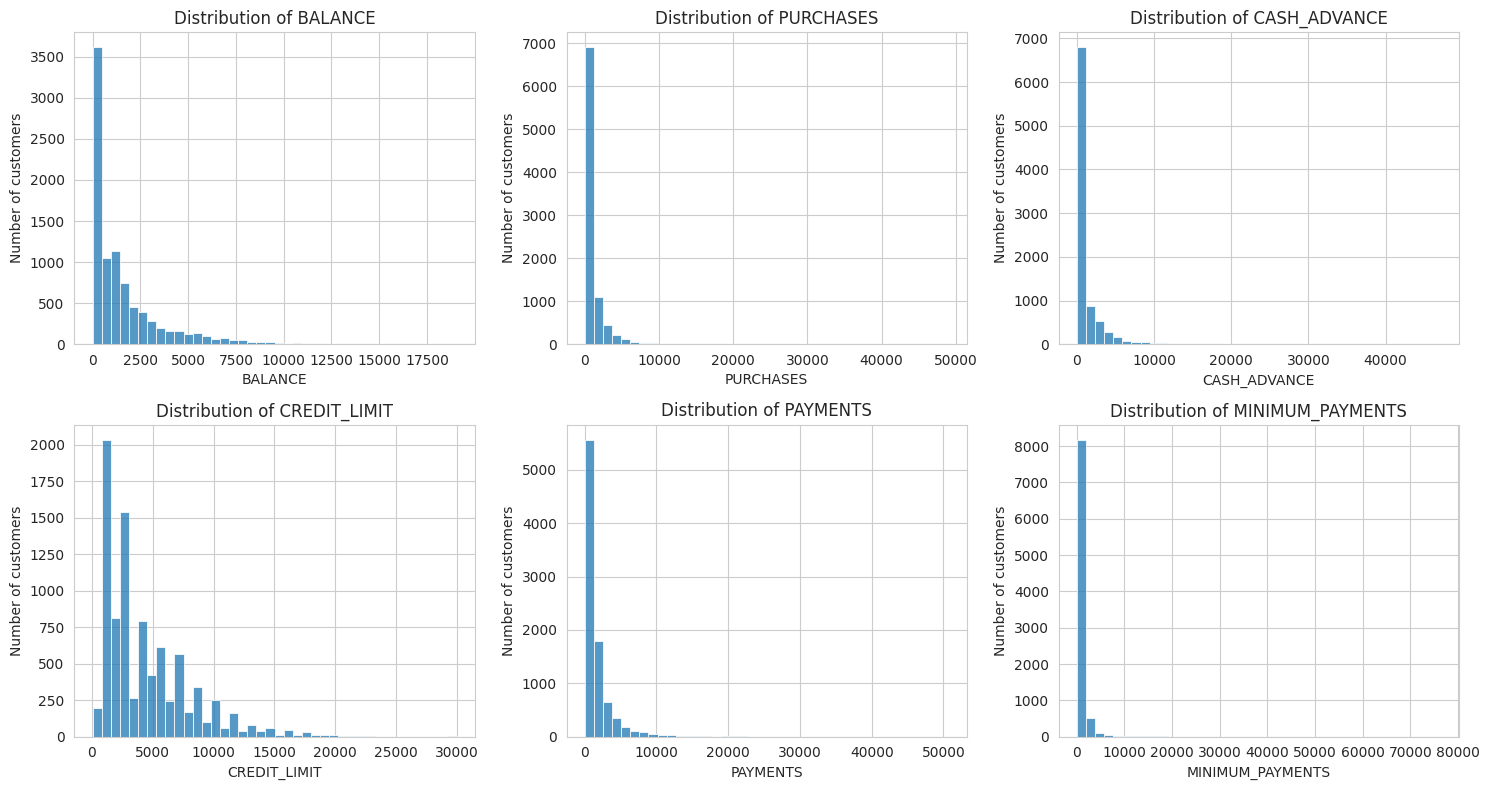

In [17]:
# histograms of key variables

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), key_cols):
    sns.histplot(df[col], bins=40, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

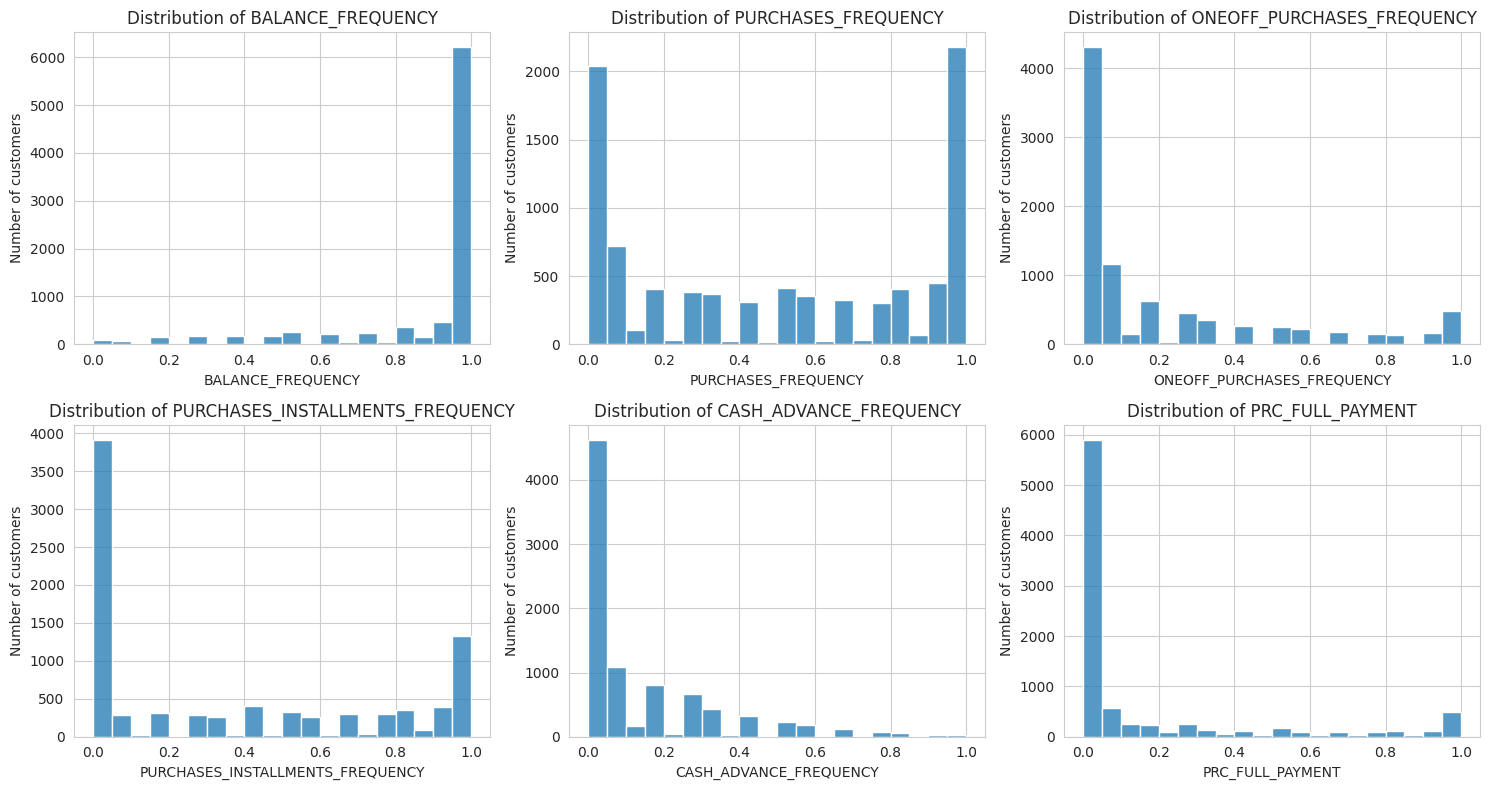

In [18]:
# histograms of frequency variables

freq_cols = [
    "BALANCE_FREQUENCY", "PURCHASES_FREQUENCY", "ONEOFF_PURCHASES_FREQUENCY",
    "PURCHASES_INSTALLMENTS_FREQUENCY", "CASH_ADVANCE_FREQUENCY", "PRC_FULL_PAYMENT",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), freq_cols):
    sns.histplot(df[col], bins=20, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

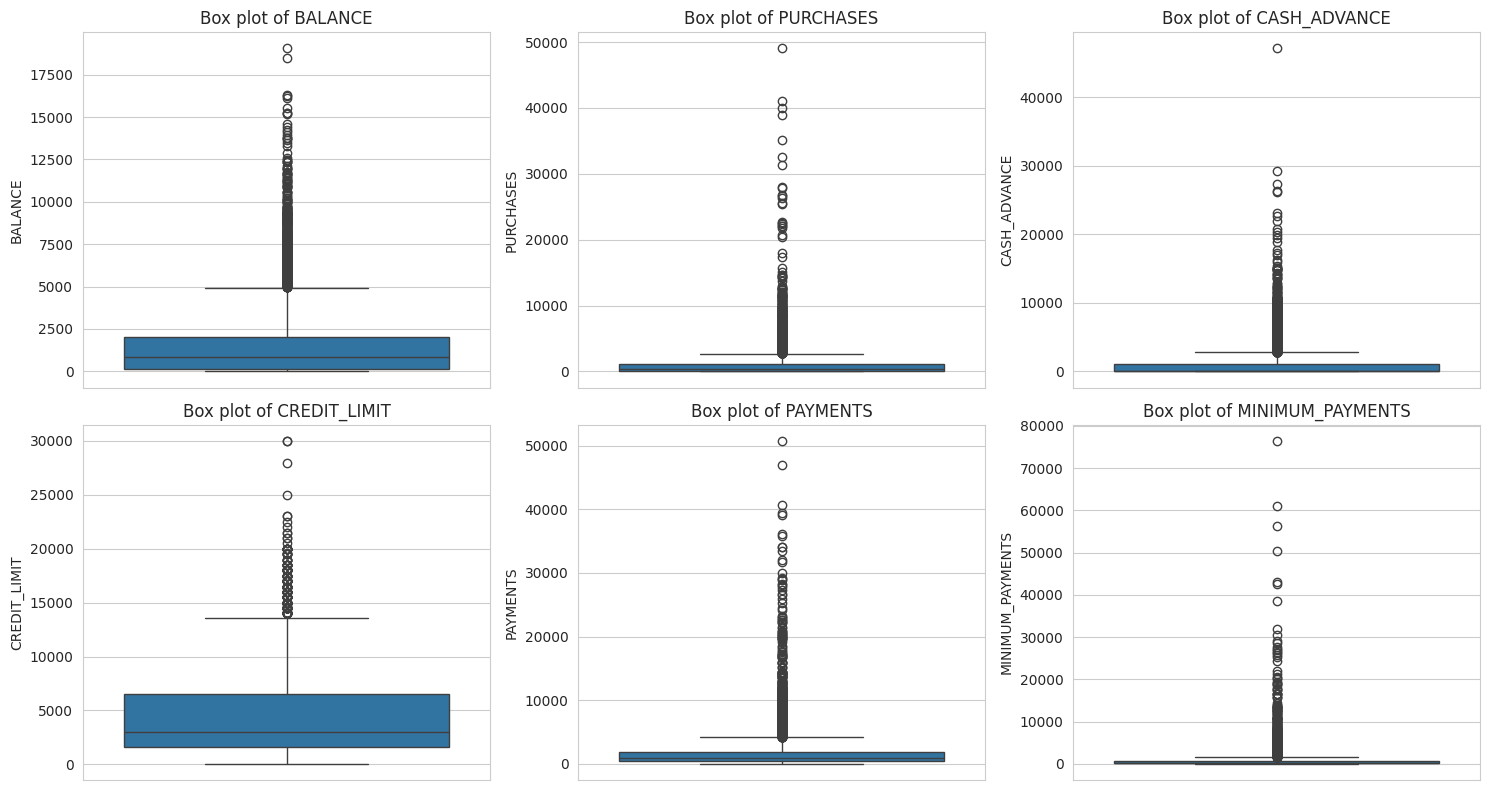

In [19]:
# box plots

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), key_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Box plot of {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

In [20]:
# how many outliers per column

# Count values above the usual box plot limit (Q3 + 1.5 * IQR)
outlier_counts = {}

for col in key_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    upper_limit = q3 + 1.5 * (q3 - q1)
    outlier_counts[col] = (df[col] > upper_limit).sum()

pd.Series(outlier_counts, name="Values above upper limit")

,Values above upper limit
BALANCE,695
PURCHASES,808
CASH_ADVANCE,1030
CREDIT_LIMIT,248
PAYMENTS,808
MINIMUM_PAYMENTS,909


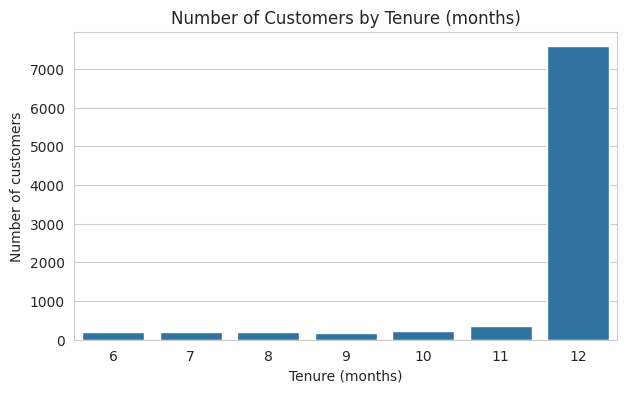

TENURE
12    0.847
11    0.041
10    0.026
6     0.023
8     0.022
7     0.021
9     0.020
Name: proportion, dtype: float64


In [21]:
# tenure bar chart

plt.figure(figsize=(7, 4))
sns.countplot(x="TENURE", data=df)
plt.title("Number of Customers by Tenure (months)")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of customers")
plt.show()

print(df["TENURE"].value_counts(normalize=True).round(3))

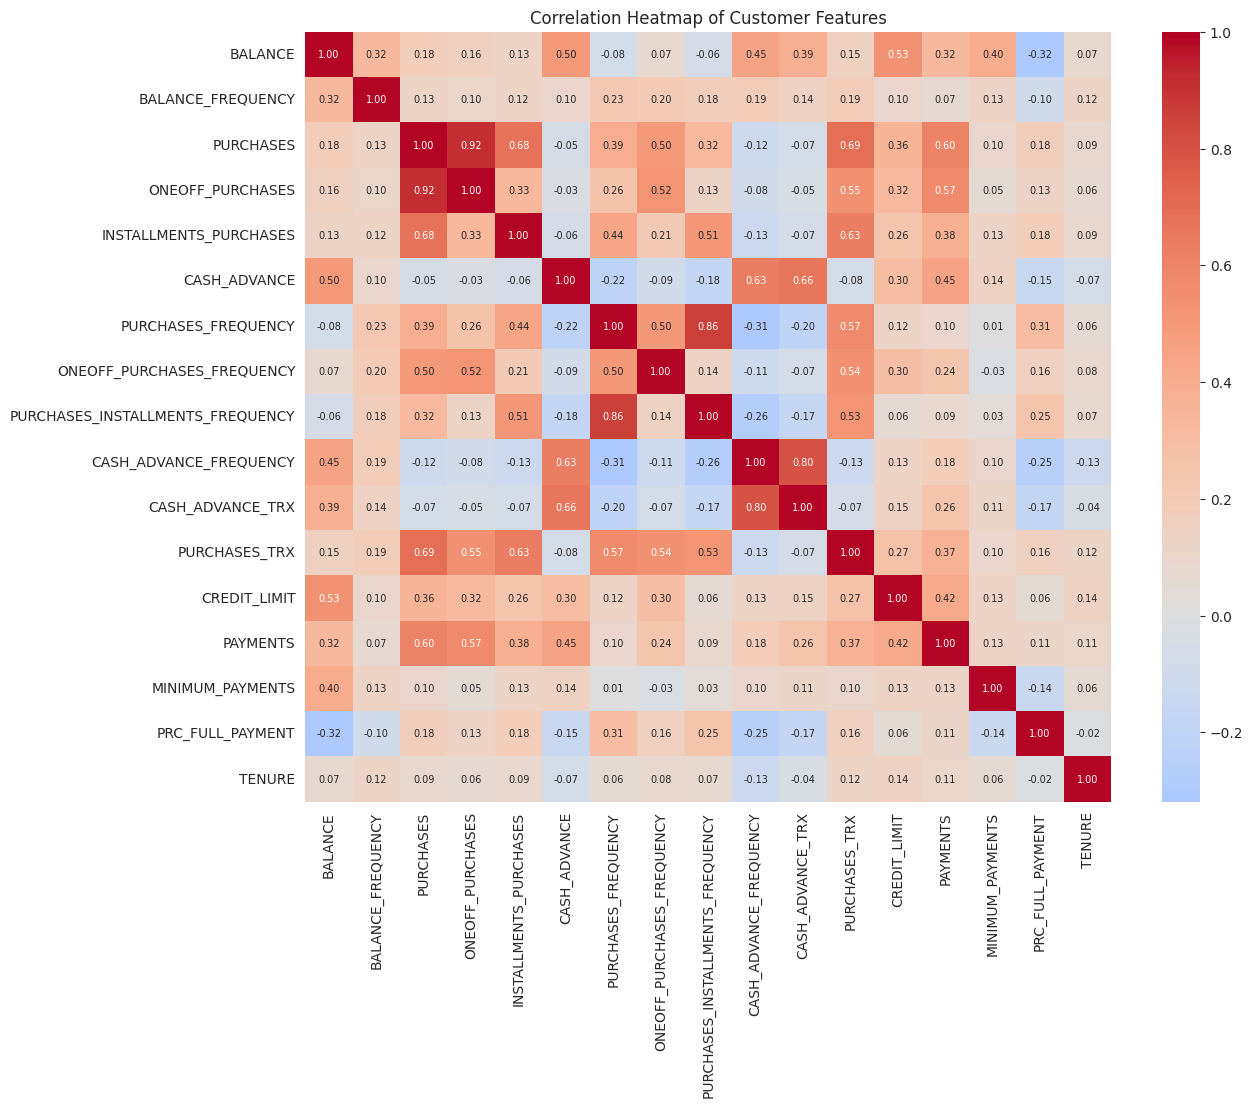

In [22]:
# correlation heatmap

plt.figure(figsize=(13, 10))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation Heatmap of Customer Features")
plt.show()

In [23]:
# strongest correlations as a list

corr = df[features].corr()

# Keep each pair once (upper triangle only)
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack().sort_values(ascending=False)

print("Top 8 positive pairs:")
print(pairs.head(8).round(2))
print()
print("Top 5 negative pairs:")
print(pairs.tail(5).round(2))

Top 8 positive pairs:
PURCHASES               ONEOFF_PURCHASES                    0.92
PURCHASES_FREQUENCY     PURCHASES_INSTALLMENTS_FREQUENCY    0.86
CASH_ADVANCE_FREQUENCY  CASH_ADVANCE_TRX                    0.80
PURCHASES               PURCHASES_TRX                       0.69
                        INSTALLMENTS_PURCHASES              0.68
CASH_ADVANCE            CASH_ADVANCE_TRX                    0.66
                        CASH_ADVANCE_FREQUENCY              0.63
INSTALLMENTS_PURCHASES  PURCHASES_TRX                       0.63
dtype: float64

Top 5 negative pairs:
CASH_ADVANCE                      PURCHASES_FREQUENCY      -0.22
CASH_ADVANCE_FREQUENCY            PRC_FULL_PAYMENT         -0.25
PURCHASES_INSTALLMENTS_FREQUENCY  CASH_ADVANCE_FREQUENCY   -0.26
PURCHASES_FREQUENCY               CASH_ADVANCE_FREQUENCY   -0.31
BALANCE                           PRC_FULL_PAYMENT         -0.32
dtype: float64


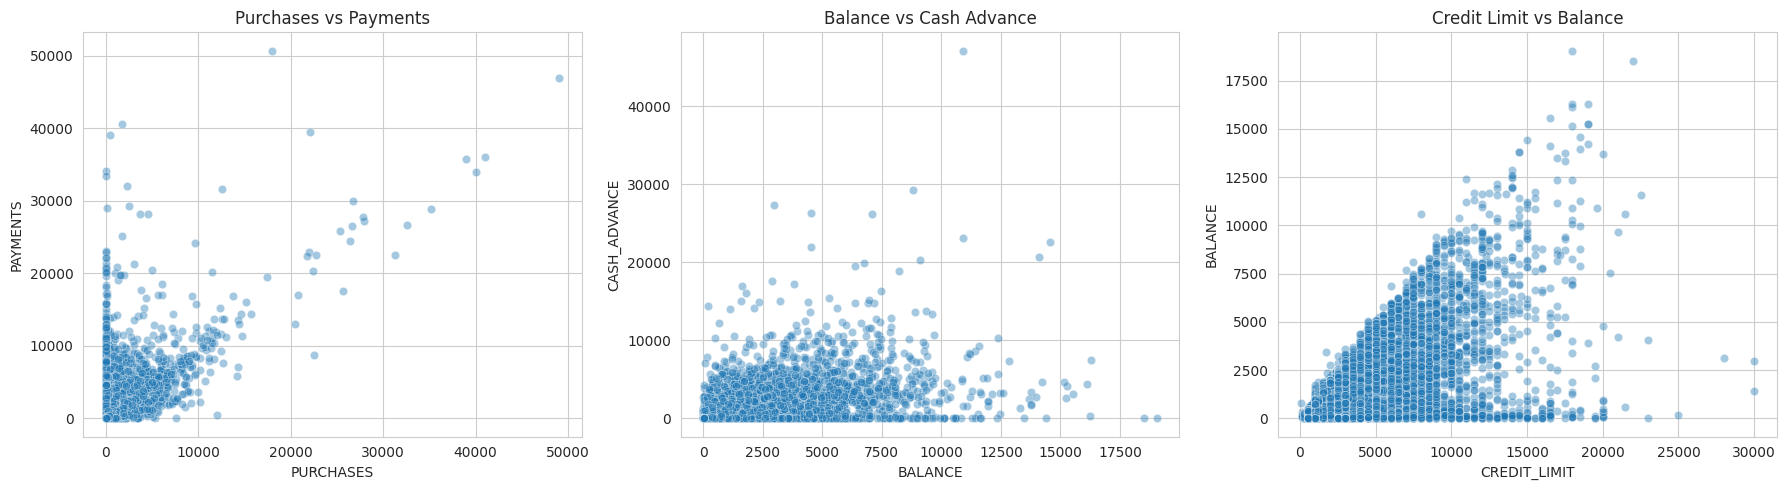

In [24]:
# scatter plots

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x="PURCHASES", y="PAYMENTS", data=df, alpha=0.4, ax=axes[0])
axes[0].set_title("Purchases vs Payments")

sns.scatterplot(x="BALANCE", y="CASH_ADVANCE", data=df, alpha=0.4, ax=axes[1])
axes[1].set_title("Balance vs Cash Advance")

sns.scatterplot(x="CREDIT_LIMIT", y="BALANCE", data=df, alpha=0.4, ax=axes[2])
axes[2].set_title("Credit Limit vs Balance")

plt.tight_layout()
plt.show()

## **Outputs**

Skew and Outliers

1. The money columns are strongly right-skewed. `MINIMUM_PAYMENTS` (13.85), `ONEOFF_PURCHASES` (10.05), and `PURCHASES` (8.14) are the worst.
2. The histograms confirm this. Most customers sit near zero, with a long tail of a few very large values.
3. Outlier counts are large: `CASH_ADVANCE` 1030, `MINIMUM_PAYMENTS` 909, `PURCHASES` and `PAYMENTS` 808 each. That is 9% to 12% of customers per column. These are not rare errors. They are a real part of the customer base.
4. `TENURE` is concentrated at 12 months (84.7%). The other six values share about 15%.

Frequency Columns

1. `BALANCE_FREQUENCY` is mostly near 1.
2. `PURCHASES_FREQUENCY` is split into two groups, one near 0 and one near 1. This suggests natural customer types.
3. `PRC_FULL_PAYMENT` is near 0 for most customers. Only a small group pays in full.

Correlations

1. `PURCHASES` and `ONEOFF_PURCHASES`: 0.92.
2. `PURCHASES_FREQUENCY` and `PURCHASES_INSTALLMENTS_FREQUENCY`: 0.86.
3. `CASH_ADVANCE_FREQUENCY` and `CASH_ADVANCE_TRX`: 0.80.
4. Cash advance features have weak or negative links with purchase features (for example -0.31 between `PURCHASES_FREQUENCY` and `CASH_ADVANCE_FREQUENCY`).

Scatter Plots

1. Purchases vs Payments: positive trend, but most customers cluster at low values.
2. Balance vs Cash Advance: no clear line. Most customers sit at low cash advance at every balance level.
3. Credit Limit vs Balance: balance rarely exceeds the limit, which makes a triangle shape.

### EDA Insights

**Insight 1: Spending and payment variables are heavily skewed with many outliers.**
- `MINIMUM_PAYMENTS` (skew 13.85), `ONEOFF_PURCHASES` (10.05), and `PURCHASES` (8.14) have the highest skew.
- Between 808 and 1030 customers per money column are above the box plot upper limit.
- Most customers sit near zero, and a few spend or borrow very large amounts.
- **Link to clustering:** K-Means uses distance, so a few extreme values can pull centroids. I will apply a log transform before scaling.

**Insight 2: Customers split into purchase users and cash advance users.**
- Cash advance variables have weak or negative correlation with purchase variables (-0.31 between `PURCHASES_FREQUENCY` and `CASH_ADVANCE_FREQUENCY`).
- `PURCHASES_FREQUENCY` has two peaks, near 0 and near 1.
- **Link to clustering:** These differences should help K-Means form separate groups, such as active shoppers and cash advance users.

**Insight 3: Several features carry overlapping information.**
- `PURCHASES` and `ONEOFF_PURCHASES` correlate at 0.92.
- `PURCHASES_FREQUENCY` and `PURCHASES_INSTALLMENTS_FREQUENCY` correlate at 0.86.
- `CASH_ADVANCE_FREQUENCY` and `CASH_ADVANCE_TRX` correlate at 0.80.
- **Link to clustering:** Overlapping features count the same behavior twice and give it extra weight. I will consider dropping some.

**Insight 4: Few customers pay their full balance, and most have 12 months of tenure.**
- Most customers have `PRC_FULL_PAYMENT` near 0. A small group pays in full.
- 84.7% of customers have `TENURE` of 12.
- **Link to clustering:** `PRC_FULL_PAYMENT` separates careful payers from revolvers. `TENURE` has little variation, so it will add little to the clusters.

### Decisions for the Next Step

1. Log transform: Justified. The skew is high and K-Means is sensitive to it. I will use `np.log1p` on the money and count columns. `log1p` handles zeros safely.
2. Do not remove outliers. They are 9% to 12% of customers and likely represent real segments, such as big spenders. Removing them would erase those groups.
3. Drop `TENURE`. 85% of customers share one value, so it has little power to separate groups. It also has skew of -2.94.
4. Handle overlap: Keep `PURCHASES`, `PURCHASES_FREQUENCY`, `CASH_ADVANCE`, and `CASH_ADVANCE_FREQUENCY`. Drop `ONEOFF_PURCHASES`, `INSTALLMENTS_PURCHASES`, `PURCHASES_TRX`, `CASH_ADVANCE_TRX`, and the two sub-frequency columns. They are largely repeated by the kept columns.
5. Keep both `ONEOFF_PURCHASES_FREQUENCY` and `PURCHASES_INSTALLMENTS_FREQUENCY`? I suggest dropping both and keeping `PURCHASES_FREQUENCY`. This keeps the model simple. We can revisit if the clusters look weak.

# 5. Feature Selection and Scaling

1. Select features that describe customer behavior and avoid repeating information.
2. Apply a log transform to the skewed money columns.
3. Scale all features with `StandardScaler`.

In [25]:
# select features

selected_features = [
    "BALANCE",
    "BALANCE_FREQUENCY",
    "PURCHASES",
    "PURCHASES_FREQUENCY",
    "CASH_ADVANCE",
    "CASH_ADVANCE_FREQUENCY",
    "CREDIT_LIMIT",
    "PAYMENTS",
    "MINIMUM_PAYMENTS",
    "PRC_FULL_PAYMENT",
]

X = df[selected_features].copy()
print("Shape of X:", X.shape)

Shape of X: (8950, 10)


In [26]:
# log transform

# Only the money columns need the log transform.
# The frequency columns are already between 0 and 1.
money_cols = [
    "BALANCE", "PURCHASES", "CASH_ADVANCE",
    "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS",
]

X_log = X.copy()
X_log[money_cols] = np.log1p(X_log[money_cols])

# Compare skew before and after
skew_compare = pd.DataFrame({
    "Before": X[money_cols].skew(),
    "After": X_log[money_cols].skew(),
}).round(2)

skew_compare

,Before,After
BALANCE,2.39,-0.86
PURCHASES,8.14,-0.76
CASH_ADVANCE,5.17,0.26
CREDIT_LIMIT,1.52,-0.10
PAYMENTS,5.91,-1.78
MINIMUM_PAYMENTS,13.85,0.27


In [27]:
# scale

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

X_scaled_df = pd.DataFrame(X_scaled, columns=selected_features)

# Each column should now have mean near 0 and standard deviation near 1
X_scaled_df.describe().T[["mean", "std"]].round(2)

,mean,std
BALANCE,0.0,1.0
BALANCE_FREQUENCY,0.0,1.0
PURCHASES,0.0,1.0
PURCHASES_FREQUENCY,0.0,1.0
CASH_ADVANCE,0.0,1.0
CASH_ADVANCE_FREQUENCY,0.0,1.0
CREDIT_LIMIT,-0.0,1.0
PAYMENTS,0.0,1.0
MINIMUM_PAYMENTS,-0.0,1.0
PRC_FULL_PAYMENT,-0.0,1.0


### Feature selection decisions

**Kept (10 features):**
1. `BALANCE`, `BALANCE_FREQUENCY`: how much and how often the customer carries a balance.
2. `PURCHASES`, `PURCHASES_FREQUENCY`: how much and how often the customer buys.
3. `CASH_ADVANCE`, `CASH_ADVANCE_FREQUENCY`: how much and how often the customer borrows cash.
4. `CREDIT_LIMIT`: the size of the credit line.
5. `PAYMENTS`, `MINIMUM_PAYMENTS`, `PRC_FULL_PAYMENT`: how the customer repays.

**Dropped:**
1. `CUST_ID`: identifier, not a behavior.
2. `TENURE`: 84.7% of customers have 12 months, so it adds little.
3. `ONEOFF_PURCHASES`, `INSTALLMENTS_PURCHASES`, `PURCHASES_TRX`: overlap with `PURCHASES` (correlations 0.92, 0.68, 0.69).
4. `ONEOFF_PURCHASES_FREQUENCY`, `PURCHASES_INSTALLMENTS_FREQUENCY`: overlap with `PURCHASES_FREQUENCY` (0.86 for installments).
5. `CASH_ADVANCE_TRX`: overlaps with `CASH_ADVANCE_FREQUENCY` (0.80).

**Transform and scaling:**
1. `np.log1p` reduces skew in the money columns without removing outliers.
2. `StandardScaler` gives every feature mean 0 and standard deviation 1.

### **Outputs**

1. Shape: `X` has 8950 rows and 10 features. No rows were lost.
2. Skew dropped sharply for all six money columns.
- `MINIMUM_PAYMENTS`: 13.85 to 0.2
- `PURCHASES`: 8.14 to -0.76
- `CASH_ADVANCE`: 5.17 to 0.26
- `BALANCE`: 2.39 to -0.86
- `CREDIT_LIMIT`: 1.52 to -0.10
3. `PAYMENTS` is the one to watch. Its skew went from 5.91 to -1.78. The tail flipped to the left. This happens because many customers have `PAYMENTS` of 0, and `log1p(0)` is 0. That creates a pile of values at the low end. It is much better than before, so I will keep it.
4. Scaling worked. Every feature has mean 0 and standard deviation 1.

# 6. Choosing the Number of Clusters

K-Means needs `n_clusters` to be set before training. I test k from 2 to 10 and use two measures:

1. **Inertia (Elbow Method):** The total squared distance from each customer to its cluster center. It always falls as k grows. I look for the point where the drop slows down.
2. **Silhouette Score:** How well each customer fits its own cluster compared with the nearest other cluster. It ranges from -1 to 1. Higher is better.

I also check that every cluster is large enough to be meaningful.

In [28]:
# run K-Means for k = 2 to 10

k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

results = pd.DataFrame({
    "k": list(k_values),
    "Inertia": np.round(inertias, 0),
    "Silhouette": np.round(silhouettes, 3),
})

results

,k,Inertia,Silhouette
0,2,66344.0,0.252
1,3,54968.0,0.251
2,4,47702.0,0.240
3,5,41544.0,0.249
4,6,38507.0,0.224
5,7,35921.0,0.233
6,8,33444.0,0.217
7,9,31750.0,0.221
8,10,30297.0,0.212


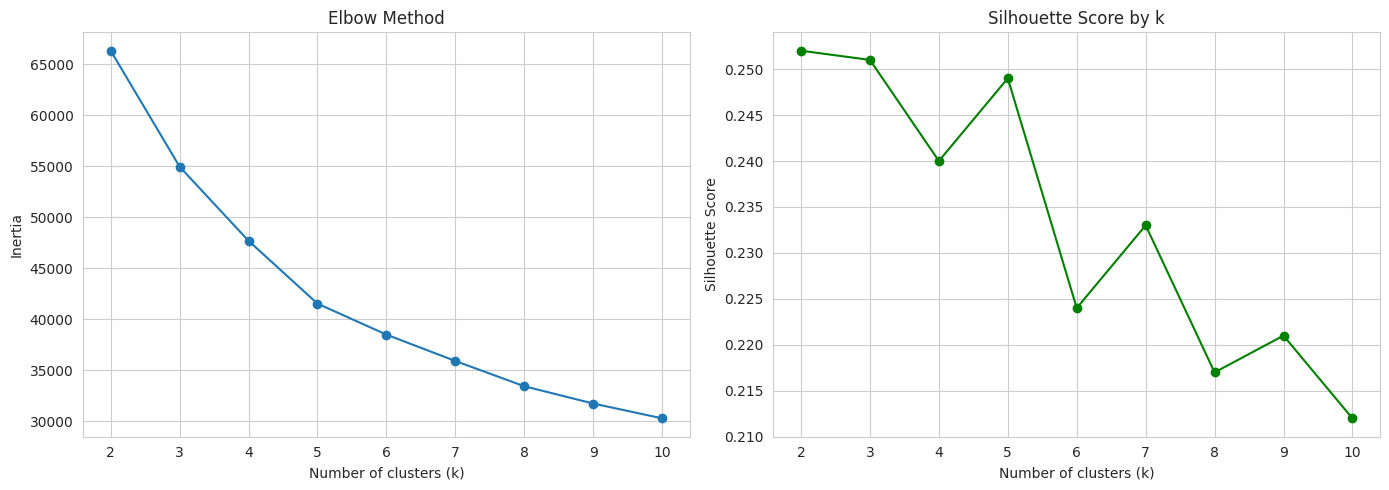

In [29]:
# plot both curves

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
axes[0].plot(results["k"], results["Inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

# Silhouette plot
axes[1].plot(results["k"], results["Silhouette"], marker="o", color="green")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [30]:
# cluster sizes for candidate k values

# Check the size of each cluster for a few reasonable choices
for k in [3, 4, 5, 6]:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    sizes = pd.Series(labels).value_counts().sort_index()
    print(f"k = {k}: {sizes.tolist()}")

k = 3: [1445, 3479, 4026]
k = 4: [1300, 3344, 1443, 2863]
k = 5: [1165, 2768, 1477, 2182, 1358]
k = 6: [2067, 1777, 1279, 1340, 1054, 1433]


What Each Part Does

1. `n_clusters=k`: The number of groups to create.
2. `random_state=42`: Fixes the random start, so results repeat.
3. `n_init=10`: Runs K-Means 10 times with different starting centers and keeps the best run. This avoids a poor start.
4. `fit_predict`: Trains the model and returns the cluster label of each customer.
5. `model.inertia_`: The inertia value for the Elbow plot.
6. `silhouette_score`: Takes the scaled data and the labels. It can be slow on 8950 rows across 9 values of k, so allow a minute or two.
7. Cluster size check: A cluster with only a handful of customers is usually not useful for business.

How to Decide

1. Find where the inertia curve bends.
2. Find which k has a high Silhouette Score.
3. Reject any k that gives a tiny cluster.
4. Prefer a smaller k when scores are close, because fewer segments are easier to explain and act on.
5. Be honest if the elbow is not clear. With customer data like this, it often is not.

### **Outputs**

Elbow (Drop in Inertia from One k to the Next)

| Step   | Drop  |
| ------ | ----- |
| 2 to 3 | 11376 |
| 3 to 4 | 7266  |
| 4 to 5 | 6158  |
| 5 to 6 | 3037  |
| 6 to 7 | 2586  |

1. The drops stay large until k = 5.
2. They fall by about half after k = 5.
3. The elbow is soft, but k = 5 is the best candidate.

Silhouette

1. k = 2 (0.252), k = 3 (0.251), and k = 5 (0.249) are almost tied.
2. k = 4 dips to 0.240, then k = 5 rises again.
3. After k = 5, scores fall to 0.224 or lower.
4. All scores are low. Values near 0.25 mean weak to moderate structure, with some overlap between clusters. This is common for customer behavior data, because behavior changes gradually and rarely forms sharp groups.

Cluster Sizes

1. k = 5 sizes are 1165, 2768, 1477, 2182, and 1358.
2. The smallest cluster holds 13% of customers, so no cluster is tiny.

Decision: k = 5

1. The elbow slows after 5.
2. The Silhouette Score at k = 5 is nearly equal to k = 2 and k = 3.
3. k = 2 or 3 would give groups too broad for targeting savings, loans, and wealth offers.
4. Cluster sizes are balanced.

### Choosing k

1. **Elbow:** The drop in inertia is large up to k = 5 (6158 from k = 4 to 5) and about half as large from k = 5 to 6 (3037). The elbow is not sharp, but it points to k = 5.
2. **Silhouette:** k = 2 (0.252), k = 3 (0.251), and k = 5 (0.249) score almost the same. Scores drop for k of 6 or more.
3. **Cluster sizes:** At k = 5 every cluster holds at least 13% of customers (1165 to 2768).
4. **Business value:** Two or three segments are too broad for targeted offers. Five segments give more useful groups with a similar score.

**Decision:** k = 5.

**Limitation:** All Silhouette Scores are about 0.25. This means the groups overlap somewhat. The segments describe tendencies, not sharp boundaries.


# 7. Train the Final K-Means Model

I train K-Means with k = 5 on the scaled data. Then I attach the cluster labels to a copy of the cleaned data. The copy keeps real values, so I can describe each cluster in real amounts.

In [31]:
# train

final_k = 5

kmeans = KMeans(n_clusters=final_k, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

print("Final inertia:", round(kmeans.inertia_, 0))
print("Final Silhouette Score:", round(silhouette_score(X_scaled, cluster_labels), 3))

Final inertia: 41544.0
Final Silhouette Score: 0.249


In [32]:
# add labels to a copy

df_clustered = df.copy()
df_clustered["CLUSTER"] = cluster_labels

df_clustered[["CUST_ID", "CLUSTER"]].head()

,CUST_ID,CLUSTER
0,C10001,0
1,C10002,3
2,C10003,1
3,C10004,0
4,C10005,1


In [33]:
# cluster sizes

sizes = df_clustered["CLUSTER"].value_counts().sort_index()

size_table = pd.DataFrame({
    "Customers": sizes,
    "Percent": (sizes / len(df_clustered) * 100).round(1),
})

size_table

,Customers,Percent
CLUSTER,,
0,1165,13.0
1,2768,30.9
2,1477,16.5
3,2182,24.4
4,1358,15.2


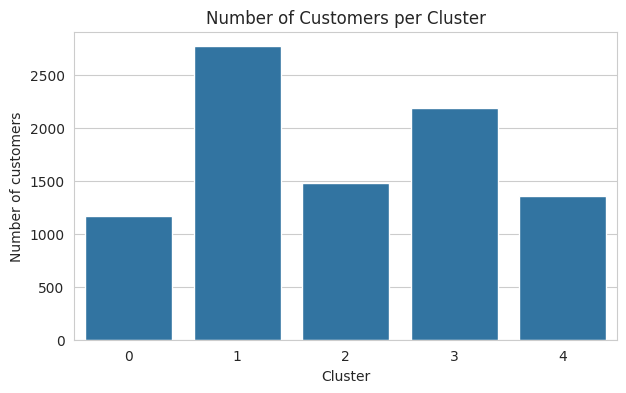

In [34]:
# size bar chart

plt.figure(figsize=(7, 4))
sns.countplot(x="CLUSTER", data=df_clustered)
plt.title("Number of Customers per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of customers")
plt.show()

What Each Part Does

1. `final_k = 5`: Stores our decision in one place.
2. `KMeans(...)`: Uses the same `random_state` and `n_init` as before. Results should match the k = 5 row in Step 6 (Silhouette 0.249, inertia about 41544).
3. `fit_predict(X_scaled)`: Trains the model on the scaled, log-transformed data. Returns one label (0 to 4) per customer.
4. `df_clustered`: A copy of the cleaned data with a `CLUSTER` column. We use `df` and not `X_scaled`, so the profiles show real amounts.
5. Cluster numbers have no order. Cluster 0 is not “better” than cluster 4. They are only names.
6. Size table and chart: Confirm that no cluster is tiny or dominant.

### Final model results

1. K-Means with k = 5 gives an inertia of 41544 and a Silhouette Score of 0.249. These match the k = 5 row from the search in section 6.
2. Cluster sizes: 1165 (13.0%), 2768 (30.9%), 1477 (16.5%), 2182 (24.4%), 1358 (15.2%).
3. No cluster is very small, so each group is large enough to be useful.
4. Cluster numbers are only labels. They have no order.

# 5. Model Evaluation

Clustering has no true labels, so classification accuracy does not apply. I use three measures instead:

1. **Inertia:** How tight the clusters are. Lower is tighter. It always falls as k grows, so it cannot judge quality alone.
2. **Silhouette Score:** How well each customer fits its own cluster. Range is -1 to 1. Higher is better.
3. **Cluster sizes:** Show whether any group is tiny or dominant.

I compare k = 3, 4, and 5 and then justify the final choice.

In [35]:
# comparison table

rows = []

for k in [3, 4, 5]:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    sizes = pd.Series(labels).value_counts()

    rows.append({
        "k": k,
        "Inertia": round(model.inertia_, 0),
        "Silhouette": round(silhouette_score(X_scaled, labels), 3),
        "Smallest cluster (%)": round(sizes.min() / len(labels) * 100, 1),
        "Largest cluster (%)": round(sizes.max() / len(labels) * 100, 1),
    })

comparison = pd.DataFrame(rows)
comparison

,k,Inertia,Silhouette,Smallest cluster (%),Largest cluster (%)
0,3,54968.0,0.251,16.1,45.0
1,4,47702.0,0.240,14.5,37.4
2,5,41544.0,0.249,13.0,30.9


In [36]:
# silhouette per cluster for the final model

from sklearn.metrics import silhouette_samples

sample_scores = silhouette_samples(X_scaled, cluster_labels)

per_cluster = (
    pd.DataFrame({"CLUSTER": cluster_labels, "Silhouette": sample_scores})
    .groupby("CLUSTER")["Silhouette"]
    .agg(["mean", lambda s: (s < 0).mean() * 100])
    .round(3)
)
per_cluster.columns = ["Mean silhouette", "% with negative score"]
per_cluster

,Mean silhouette,% with negative score
CLUSTER,,
0,0.156,20.515
1,0.237,1.192
2,0.227,1.016
3,0.287,0.642
4,0.316,0.000


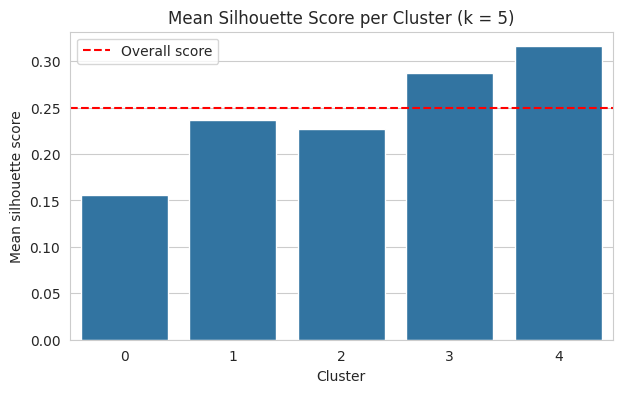

In [37]:
# plot the per-cluster scores

plt.figure(figsize=(7, 4))
sns.barplot(x=per_cluster.index, y=per_cluster["Mean silhouette"])
plt.axhline(silhouette_score(X_scaled, cluster_labels), color="red", linestyle="--", label="Overall score")
plt.title("Mean Silhouette Score per Cluster (k = 5)")
plt.xlabel("Cluster")
plt.ylabel("Mean silhouette score")
plt.legend()
plt.show()

What Each Part Does

1. Comparison table: Puts the three candidate k values side by side. The justification then rests on numbers, not one result.
2. `silhouette_samples`: Gives one score per customer. Averaging by cluster shows which groups are well separated and which overlap.
3. % with negative score: A negative score means the customer sits closer to another cluster. A high share points to a weak cluster.
4. Red line: The overall score. Clusters below it are weaker than average. Clusters above it are stronger.

### Evaluation results

**Comparison of k values**

| k | Inertia | Silhouette | Smallest cluster | Largest cluster |
|---|---|---|---|---|
| 3 | 54968 | 0.251 | 16.1% | 45.0% |
| 4 | 47702 | 0.240 | 14.5% | 37.4% |
| 5 | 41544 | 0.249 | 13.0% | 30.9% |

**Why k = 5**
1. The Silhouette Score at k = 5 (0.249) is almost the same as k = 3 (0.251).
2. Inertia is about 24% lower than k = 3, so customers sit closer to their cluster centers.
3. Cluster sizes are more balanced. The largest cluster drops from 45.0% to 30.9%.
4. k = 4 has the lowest Silhouette Score and no clear benefit.
5. Five segments give finer groups for targeting offers.

**Per-cluster quality (k = 5)**
1. Clusters 3 (0.287) and 4 (0.316) are the best separated. Cluster 4 has no negative scores.
2. Clusters 1 (0.237) and 2 (0.227) are moderate. About 1% of their customers have a negative score.
3. Cluster 0 is the weakest. Its mean is 0.156, and 20.5% of its customers have a negative score. It overlaps with other clusters.

**Metric note:** The dataset has no true segment labels. Classification accuracy does not apply, so Silhouette Score is the main metric.

**Limitation:** The overall Silhouette Score of 0.249 shows moderate structure with overlap. The clusters describe tendencies, not sharp boundaries.

# 9. Visualize and Profile Clusters

1. Plot customers on pairs of key features, colored by cluster.
2. Build a profile table with the average real values per cluster.
3. Compare clusters with bar charts.
4. Name each cluster from its observed values.

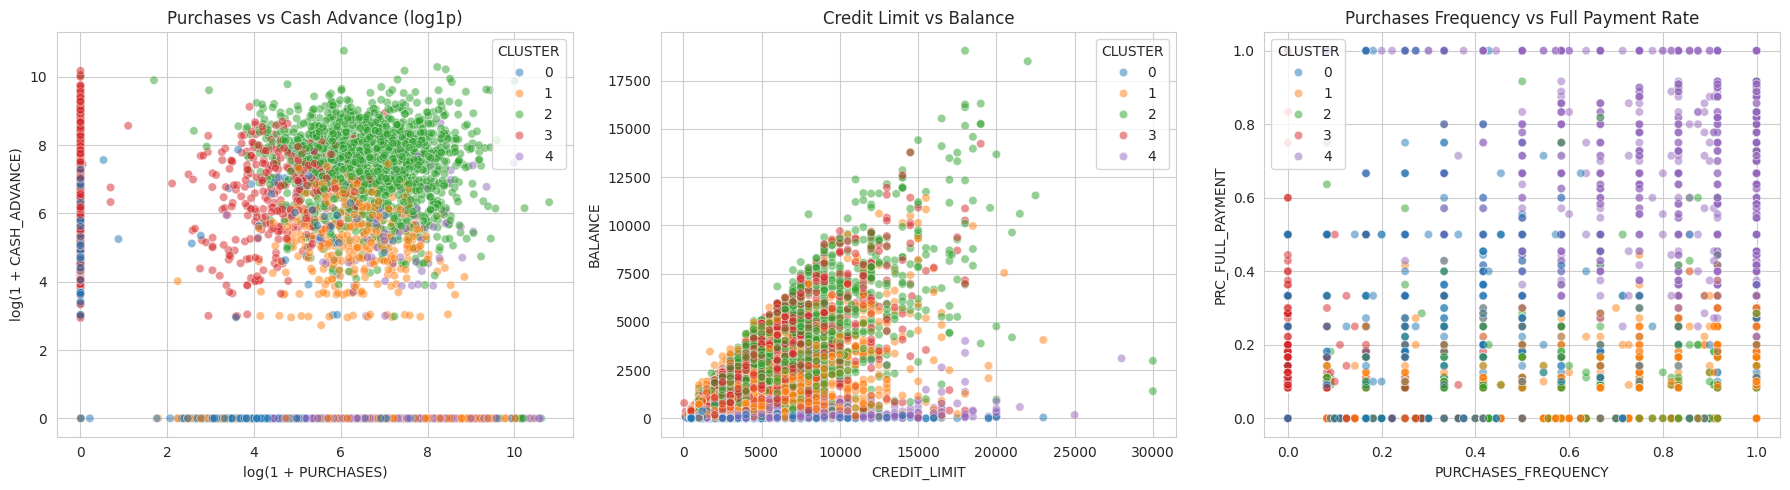

In [46]:
# scatter plots colored by cluster

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=np.log1p(df_clustered["PURCHASES"]),
                y=np.log1p(df_clustered["CASH_ADVANCE"]),
                hue=df_clustered["CLUSTER"], palette="tab10",
                alpha=0.5, ax=axes[0])
axes[0].set_title("Purchases vs Cash Advance (log1p)")
axes[0].set_xlabel("log(1 + PURCHASES)")
axes[0].set_ylabel("log(1 + CASH_ADVANCE)")

sns.scatterplot(x="CREDIT_LIMIT", y="BALANCE", hue="CLUSTER", palette="tab10",
                data=df_clustered, alpha=0.5, ax=axes[1])
axes[1].set_title("Credit Limit vs Balance")

sns.scatterplot(x="PURCHASES_FREQUENCY", y="PRC_FULL_PAYMENT", hue="CLUSTER", palette="tab10",
                data=df_clustered, alpha=0.5, ax=axes[2])
axes[2].set_title("Purchases Frequency vs Full Payment Rate")

plt.tight_layout()
plt.show()

In [40]:
# profile table with real values

profile_cols = [
    "BALANCE", "BALANCE_FREQUENCY", "PURCHASES", "PURCHASES_FREQUENCY",
    "CASH_ADVANCE", "CASH_ADVANCE_FREQUENCY", "CREDIT_LIMIT",
    "PAYMENTS", "MINIMUM_PAYMENTS", "PRC_FULL_PAYMENT",
]

# Mean shows the average. Median is less affected by outliers.
profile_mean = df_clustered.groupby("CLUSTER")[profile_cols].mean().round(2)
profile_median = df_clustered.groupby("CLUSTER")[profile_cols].median().round(2)

print("Mean values per cluster:")
display(profile_mean)

print("Median values per cluster:")
display(profile_median)

Mean values per cluster:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,PURCHASES_FREQUENCY,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT
CLUSTER,,,,,,,,,,
0,49.18,0.39,288.83,0.30,172.90,0.03,3411.74,693.85,143.16,0.13
1,1263.94,0.97,1314.43,0.68,46.83,0.02,3991.07,1355.02,845.02,0.03
2,3650.12,0.98,1664.94,0.65,2766.15,0.34,6568.05,3310.95,1784.11,0.04
3,2206.69,0.94,18.91,0.02,1969.90,0.28,3922.99,1592.45,998.42,0.03
4,176.70,0.89,1843.50,0.84,33.82,0.01,5111.11,1905.44,178.53,0.74


Median values per cluster:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,PURCHASES_FREQUENCY,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT
CLUSTER,,,,,,,,,,
0,16.00,0.36,140.04,0.17,0.00,0.00,2500.0,259.02,107.91,0.0
1,916.34,1.00,694.96,0.75,0.00,0.00,3000.0,775.16,321.08,0.0
2,2881.25,1.00,858.50,0.70,1881.77,0.27,6000.0,1874.95,1038.18,0.0
3,1520.01,1.00,0.00,0.00,1238.40,0.25,3000.0,749.98,491.73,0.0
4,86.78,1.00,925.90,1.00,0.00,0.00,4000.0,1045.50,164.00,0.8


In [41]:
# extra columns not used for clustering

# These features were dropped from clustering. Checking them tests whether the clusters make sense.
extra_cols = ["ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "PURCHASES_TRX", "CASH_ADVANCE_TRX", "TENURE"]

df_clustered.groupby("CLUSTER")[extra_cols].mean().round(2)

,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,PURCHASES_TRX,CASH_ADVANCE_TRX,TENURE
CLUSTER,,,,,
0,164.51,124.92,4.57,0.54,11.27
1,778.74,535.99,20.68,0.27,11.71
2,1026.39,638.79,23.32,8.93,11.55
3,16.36,2.59,0.30,6.57,11.38
4,1033.47,810.56,25.02,0.13,11.52


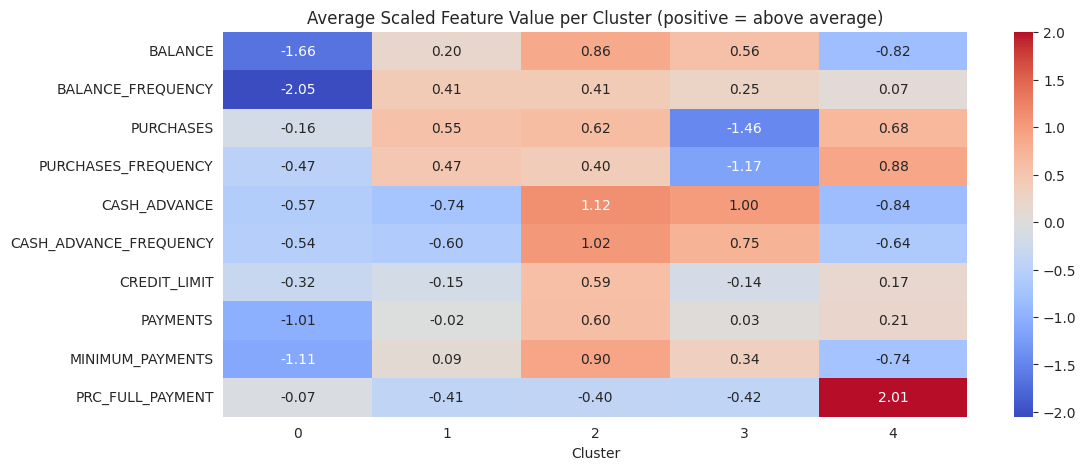

In [42]:
# bar charts of key features

# Scaled means make features with different units comparable on one chart
cluster_means_scaled = (
    X_scaled_df.assign(CLUSTER=cluster_labels)
    .groupby("CLUSTER")
    .mean()
)

plt.figure(figsize=(12, 5))
sns.heatmap(cluster_means_scaled.T, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Average Scaled Feature Value per Cluster (positive = above average)")
plt.xlabel("Cluster")
plt.show()

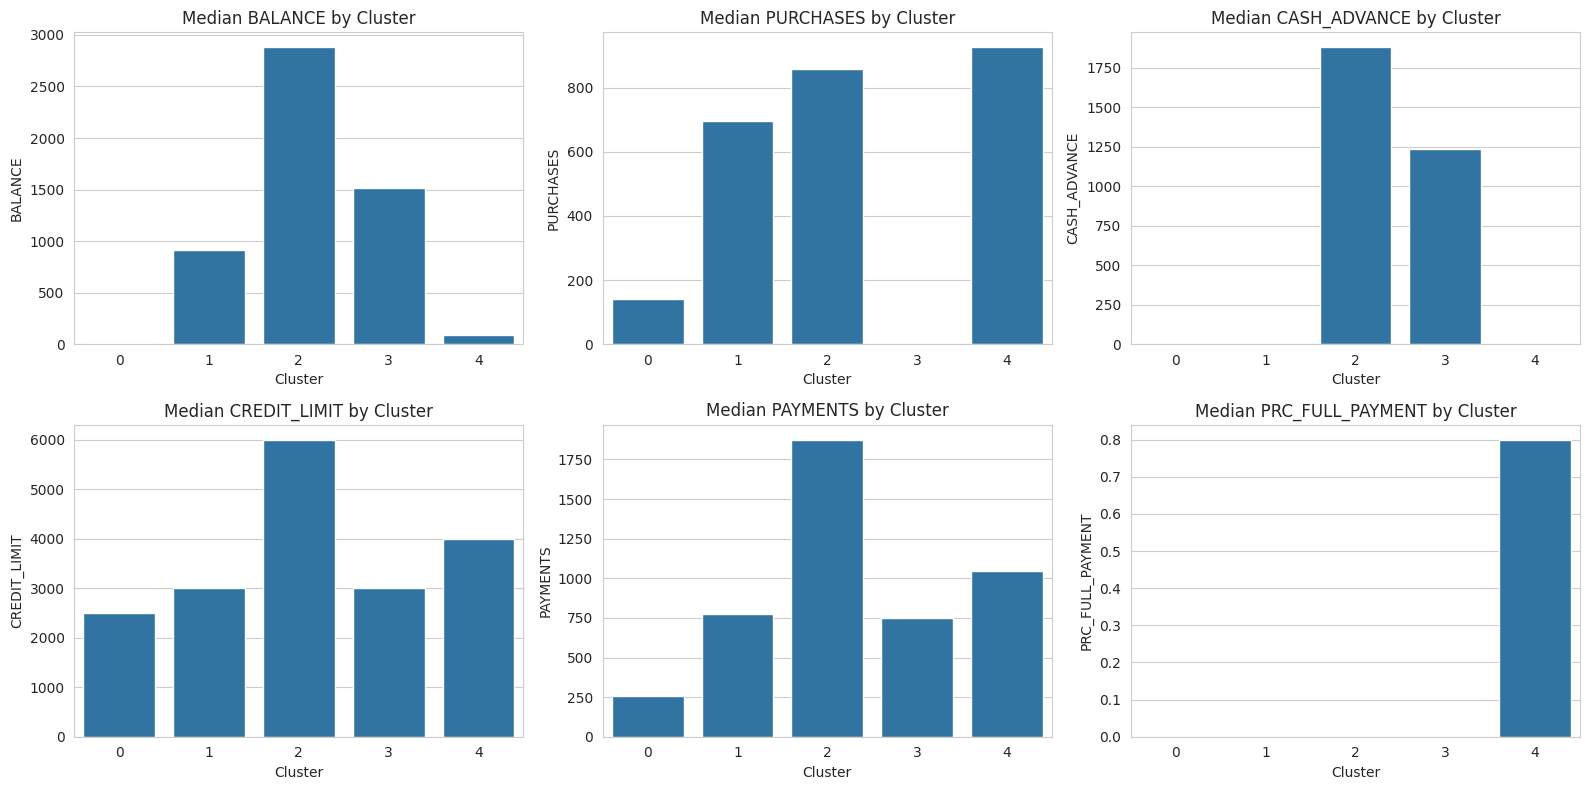

In [43]:
# key feature bar charts

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
bar_cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]

for ax, col in zip(axes.flatten(), bar_cols):
    sns.barplot(x=profile_median.index, y=profile_median[col], ax=ax)
    ax.set_title(f"Median {col} by Cluster")
    ax.set_xlabel("Cluster")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

What Each Part Does

1. Scatter plots: Show how clusters separate on the features that matter most. The `symlog` scale spreads out the crowded low values.
2. Mean and median tables: Give real amounts per cluster. I show both because the means are pulled up by outliers. When they differ a lot, trust the median for a typical customer.
3. Extra columns table: `ONEOFF_PURCHASES`, `INSTALLMENTS_PURCHASES`, `PURCHASES_TRX`, `CASH_ADVANCE_TRX`, and `TENURE` were not used to build the clusters. If they differ clearly between clusters, it supports the segments. It also shows what type of purchases each group makes.
4. Scaled heatmap: Shows at a glance what each cluster is high or low in. Red means above average. Blue means below average.
5. Median bar charts: Make the differences easy to see.

Limits of These Plots

A scatter plot shows only two features at a time. Clusters will overlap in any single plot. This is expected, and the heatmap and profile tables are the better evidence.

### Cluster profiles

The names below come from the median values in the profile tables and the scaled heatmap.

| Cluster | Customers | Name | Key evidence |
|---|---|---|---|
| 0 | 1165 (13.0%) | Low-activity | Low balance (16), low purchases (140), low payments (259) |
| 1 | 2768 (30.9%) | Regular buyers with a balance | Purchases 695, no cash advance, balance 916 |
| 2 | 1477 (16.5%) | High-limit heavy users | Limit 6000, balance 2881, cash advance 1882 |
| 3 | 2182 (24.4%) | Cash advance users | No purchases, cash advance 1238, balance 1520 |
| 4 | 1358 (15.2%) | Full payers | Buys often (1.00), full payment 0.80, balance 87 ||

**Supporting evidence from features not used in clustering**
1. Cluster 3 averages 6.57 cash advance transactions and 0.30 purchase transactions.
2. Cluster 4 averages 25.02 purchase transactions and 0.13 cash advance transactions.
3. `TENURE` stays between 11.27 and 11.71, so it does not drive the groups.

**Observation:** Cluster 0 is the weakest group (Silhouette 0.156). It combines low activity on all features, so it overlaps with other clusters.

**Limitation of the plots:** Each scatter plot shows only two of the ten features, so clusters overlap in any single view.

# 10. Findings, Limitations, and Conclusion

### Key findings
1. K-Means with k = 5 found five groups with different behavior: low-activity users, regular revolvers, high-limit cash and purchase users, cash advance dependents, and full payers.
2. The two clearest groups are cluster 3 (cash advances without purchases) and cluster 4 (frequent buyers who pay in full). They have the highest per-cluster Silhouette scores (0.287 and 0.316).
3. The main split in the data is between purchase behavior, cash advance behavior, and payment behavior.

### Model summary
1. Features: 10 behavior columns. Money columns were log-transformed and all features were scaled.
2. Final model: K-Means, k = 5, `random_state = 42`, `n_init = 10`.
3. Inertia: 41544. Silhouette Score: 0.249.
4. Cluster sizes: 13.0% to 30.9%.

### Limitations
1. The Silhouette Score of 0.249 shows moderate structure. Clusters overlap, mainly cluster 0.
2. K-Means assumes round, similar-sized groups. Customer behavior often does not fit this.
3. The data covers 6 months. Behavior may change over a longer period.
4. `MINIMUM_PAYMENTS` was filled with the median for 313 customers. Most of them had zero payments, so zero may have been a better fill value.
5. No true segment labels exist. Classification accuracy cannot be computed, so the Silhouette Score is the main metric.
6. Cluster names are interpretations. They are not proven customer types.

### Possible improvements
1. Test a different feature set, for example adding `PURCHASES_TRX`.
2. Fill `MINIMUM_PAYMENTS` with 0 and check whether the clusters change.
3. Validate segments with business data, such as default rates or product uptake.

### Conclusion
The model gives five usable customer segments with different spending, cash advance, and payment behavior. The clusters have moderate separation and can guide first-stage targeting for savings plans, loans, and wealth management offers. They should be validated with business data before use.